# 15 — Daytime-Only Evaluation

All-hours metrics are inflated because predicting **GHI = 0 at night is trivially easy**.  
This notebook re-evaluates Chronos on three hour-of-day slices using saved predictions from NB07:

| Slice | Hours (IST) | Description |
|-------|-------------|-------------|
| **All hours** | 0–23 | Baseline (includes nighttime zeros) |
| **Daytime** | wherever GHI_true > 10 W/m² | Sun-up hours only |
| **Morning** | 05:00–12:00 | Rising irradiance — hardest to forecast |
| **Afternoon** | 12:00–19:00 | Peak + declining irradiance |

In [1]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from pathlib import Path

sys.path.insert(0, os.path.abspath('.'))

from utils.city_config import (
    CITY_METADATA, get_test_cities,
    CONTEXT_LENGTH, FORECAST_HORIZON, STRIDE,
    TEST_START
)
from utils.metrics import compute_all_metrics
from utils.plotting import setup_plot_style, CITY_COLORS

setup_plot_style()

# ── Constants ─────────────────────────────────────────────────────────────────
GHI_THRESHOLD  = 10    # W/m²  — anything below this is "nighttime"
MORNING_START  = 5     # 05:00 IST
MORNING_END    = 12    # up to but not including 12:00
AFTERNOON_END  = 19    # up to but not including 19:00

print("Setup complete.")

Setup complete.


## 1 · Reconstruct Hour-of-Day for Every Target Step

Each test window has a 24-step target. Since we know windows are **stride-24** and windows start  
at the first forecast hour, we pull the exact IST timestamp for each step from the processed parquet.

In [2]:
def get_hour_matrix(city: str, n_windows: int) -> np.ndarray:
    """
    Returns (n_windows, 24) array of hour-of-day (0–23) for every target step.
    Reads timestamps from the processed parquet file.
    Falls back to modular arithmetic if parquet is unavailable.
    """
    pq_path = f'data/processed/parquet/{city}_processed.parquet'
    if os.path.exists(pq_path):
        df = pd.read_parquet(pq_path, columns=['timestamp'])
        df['timestamp'] = pd.to_datetime(df['timestamp'])
        test_df = df[df['timestamp'] >= TEST_START].reset_index(drop=True)
        hours = []
        for i in range(n_windows):
            forecast_start_idx = i * STRIDE + CONTEXT_LENGTH
            if forecast_start_idx < len(test_df):
                t0 = test_df['timestamp'].iloc[forecast_start_idx]
            else:
                # Extrapolate
                t0 = test_df['timestamp'].iloc[-1] + pd.Timedelta(
                    hours=(forecast_start_idx - len(test_df) + 1))
            window_hours = [(t0 + pd.Timedelta(hours=h)).hour for h in range(FORECAST_HORIZON)]
            hours.append(window_hours)
        return np.array(hours, dtype=np.int8)
    else:
        # Fallback: assume all windows start at hour 0
        print(f"  [warn] No parquet for {city}; using modular fallback")
        row = np.arange(FORECAST_HORIZON, dtype=np.int8)
        return np.tile(row, (n_windows, 1))


def metrics_on_mask(y_true_flat, y_pred_flat, mask_flat):
    """Compute metrics on a boolean mask. Returns dict."""
    if mask_flat.sum() < 10:
        return None
    return compute_all_metrics(y_true_flat[mask_flat], y_pred_flat[mask_flat])


print("Helper functions defined.")

Helper functions defined.


## 2 · Evaluate Each Test City Across Time-of-Day Slices

In [9]:
all_rows = []   # flat records for comparison table
hour_r2_data = {}  # city -> per-hour R² (daytime-only within each hour)

for city in get_test_cities():
    tgt_path  = f'data/processed/windows/{city}_test_targets.npy'
    pred_path = f'results/unseen_validation/pred_best_{city}.npy'

    if not os.path.exists(tgt_path):
        print(f"[skip] {city}: targets not found"); continue
    if not os.path.exists(pred_path):
        print(f"[skip] {city}: predictions not found (run NB07 first)"); continue

    targets = np.load(tgt_path)          # (N, 24)
    preds   = np.load(pred_path)         # (N, 24)
    N       = min(len(targets), len(preds))
    targets, preds = targets[:N], preds[:N]

    hour_mat = get_hour_matrix(city, N)  # (N, 24)

    y_true = targets.flatten()
    y_pred = preds.flatten()
    hours  = hour_mat.flatten()

    # ── Boolean masks ─────────────────────────────────────────────────────────
    mask_all       = np.ones(len(y_true), dtype=bool)
    mask_daytime   = y_true > GHI_THRESHOLD
    mask_morning   = (hours >= MORNING_START) & (hours < MORNING_END)
    mask_afternoon = (hours >= MORNING_END)   & (hours < AFTERNOON_END)
    mask_daytime_am = mask_morning   & mask_daytime
    mask_daytime_pm = mask_afternoon & mask_daytime

    info = CITY_METADATA[city]
    base = dict(City=city.title(), Climate=info['climate_zone'])

    for label, mask in [
        ('All Hours',        mask_all),
        ('Daytime (>10)',    mask_daytime),
        ('Morning 5-12h',    mask_morning),
        ('Afternoon 12-19h', mask_afternoon),
        ('Daytime Morning',  mask_daytime_am),
        ('Daytime Afternoon',mask_daytime_pm),
    ]:
        m = metrics_on_mask(y_true, y_pred, mask)
        if m:
            row = {**base, 'Slice': label, 'N_hrs': int(mask.sum()),
                   'R2': m['R2'], 'MAE': m['MAE'], 'RMSE': m['RMSE'], 'SMAPE': m['SMAPE']}
            all_rows.append(row)

    # ── Per-hour R² — require ≥50 samples AND mean GHI > 20 W/m² ─────────────
    # Dawn/dusk hours have near-zero variance → R² is undefined; skip them.
    per_hour = {}
    for h in range(24):
        hm = (hours == h) & mask_daytime
        if hm.sum() >= 50 and y_true[hm].mean() > 20:
            per_hour[h] = compute_all_metrics(y_true[hm], y_pred[hm])['R2']
        else:
            per_hour[h] = np.nan
    hour_r2_data[city.title()] = per_hour

    r2_all = compute_all_metrics(y_true, y_pred)['R2']
    r2_day = compute_all_metrics(y_true[mask_daytime], y_pred[mask_daytime])['R2']
    r2_am  = compute_all_metrics(y_true[mask_daytime_am], y_pred[mask_daytime_am])['R2']
    print(f"  {city.title():15s}  All={r2_all:.3f}  Daytime={r2_day:.3f}  Morning={r2_am:.3f}")

results_df = pd.DataFrame(all_rows)
print(f"\nTotal records: {len(results_df)}")

  Hyderabad        All=0.946  Daytime=0.880  Morning=0.882
  Bangalore        All=0.949  Daytime=0.883  Morning=0.883
  Kolkata          All=0.908  Daytime=0.799  Morning=0.789
  Lucknow          All=0.933  Daytime=0.860  Morning=0.867
  Jodhpur          All=0.959  Daytime=0.906  Morning=0.917

Total records: 30


## 3 · Comparison Table — All vs Daytime vs Morning

In [10]:
# Pivot: rows = city, columns = slice, values = R²
pivot_r2 = (results_df
            .pivot_table(index='City', columns='Slice', values='R2')
            .round(4))

# Reorder columns for readability
col_order = [c for c in [
    'All Hours', 'Daytime (>10)',
    'Morning 5-12h', 'Daytime Morning',
    'Afternoon 12-19h', 'Daytime Afternoon'
] if c in pivot_r2.columns]
pivot_r2 = pivot_r2[col_order]

print("R² per City & Slice\n" + "="*70)
display(pivot_r2.style
        .background_gradient(cmap='RdYlGn', vmin=0.5, vmax=1.0, axis=None)
        .format('{:.4f}'))

# MAE pivot as well
pivot_mae = (results_df
             .pivot_table(index='City', columns='Slice', values='MAE')
             .reindex(columns=col_order, fill_value=np.nan)
             .round(2))
print("\nMAE (W/m²) per City & Slice")
display(pivot_mae.style
        .background_gradient(cmap='RdYlGn_r', axis=None)
        .format('{:.2f}'))

R² per City & Slice


Slice,All Hours,Daytime (>10),Morning 5-12h,Daytime Morning,Afternoon 12-19h,Daytime Afternoon
City,,,,,,
Bangalore,0.9494,0.8831,0.9138,0.8828,0.9183,0.8827
Hyderabad,0.9460,0.8796,0.9078,0.8820,0.9142,0.8753
Jodhpur,0.9589,0.9060,0.9412,0.9169,0.9228,0.8961
Kolkata,0.9084,0.7988,0.8099,0.7886,0.8711,0.7942
Lucknow,0.9333,0.8599,0.8913,0.8671,0.8953,0.8494



MAE (W/m²) per City & Slice


Slice,All Hours,Daytime (>10),Morning 5-12h,Daytime Morning,Afternoon 12-19h,Daytime Afternoon
City,,,,,,
Bangalore,34.67,69.12,62.15,69.80,56.35,68.41
Hyderabad,33.90,67.46,61.97,68.46,53.85,66.38
Jodhpur,29.55,58.65,46.01,53.74,54.94,63.39
Kolkata,36.97,74.76,76.73,79.41,49.06,68.66
Lucknow,34.32,68.53,62.15,67.94,55.05,69.20


## 4 · Per-Hour-of-Day R² Heatmap

Each column is one hour of the day (IST). Night hours (0–4, 20–23) have R²≈1.0 trivially  
because predicting near-zero is easy — daytime hours expose the real difficulty.

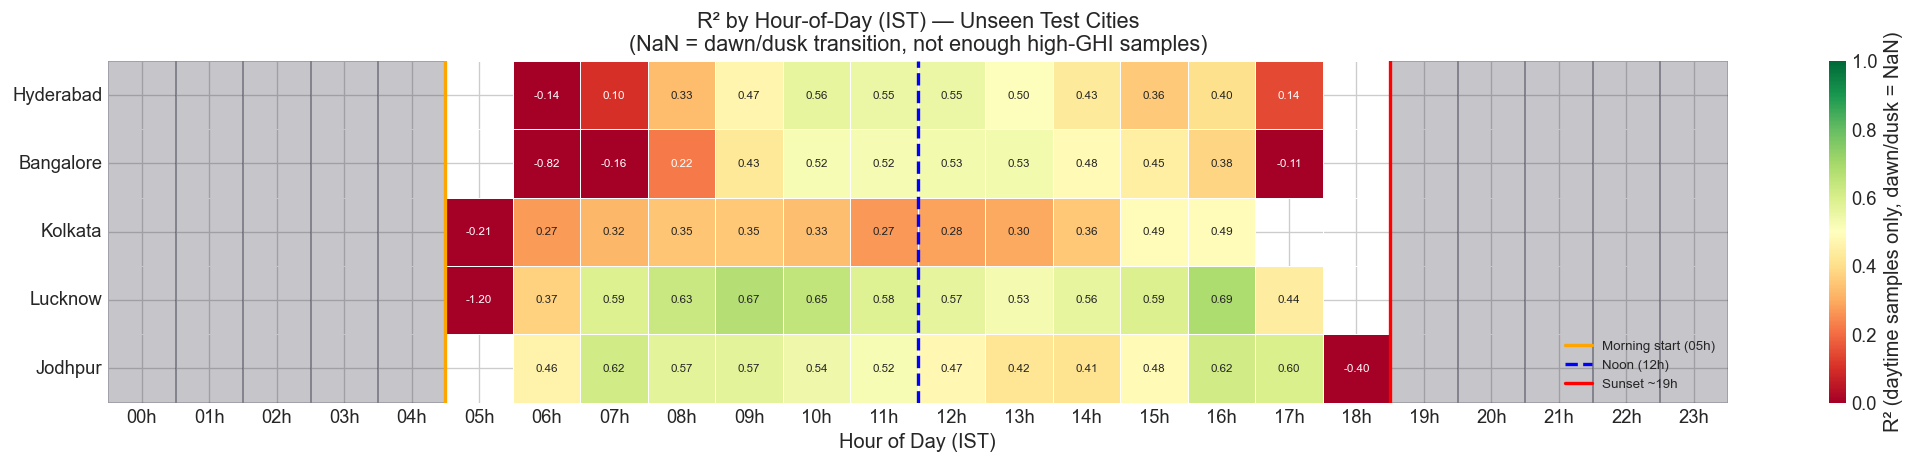

In [11]:
hour_df = pd.DataFrame(hour_r2_data).T   # cities × 24 hours
hour_df.columns = [f'{h:02d}h' for h in range(24)]

fig, ax = plt.subplots(figsize=(18, 4))
mask_nan = hour_df.isna()
sns.heatmap(
    hour_df.astype(float), ax=ax,
    cmap='RdYlGn', vmin=0.0, vmax=1.0,
    annot=True, fmt='.2f', annot_kws={'size': 7},
    linewidths=0.3, mask=mask_nan,
    cbar_kws={'label': 'R² (daytime samples only, dawn/dusk = NaN)'}
)

# Shade nighttime columns
night_cols = [i for i in range(24) if i < MORNING_START or i >= AFTERNOON_END]
for nc in night_cols:
    ax.add_patch(plt.Rectangle((nc, 0), 1, len(hour_df),
                                 fill=True, color='#1a1a2e', alpha=0.25, zorder=2))

ax.axvline(MORNING_START, color='orange', linewidth=2, label=f'Morning start ({MORNING_START:02d}h)')
ax.axvline(MORNING_END,   color='blue',   linewidth=2, linestyle='--', label=f'Noon ({MORNING_END:02d}h)')
ax.axvline(AFTERNOON_END, color='red',    linewidth=2, label=f'Sunset ~{AFTERNOON_END:02d}h')
ax.set_title('R² by Hour-of-Day (IST) — Unseen Test Cities\n'
             '(NaN = dawn/dusk transition, not enough high-GHI samples)', fontsize=13)
ax.set_xlabel('Hour of Day (IST)')
ax.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.savefig('results/figures/15_hour_r2_heatmap.png', dpi=200, bbox_inches='tight')
plt.show()

## 5 · Grouped Bar Chart — R² All vs Daytime vs Morning

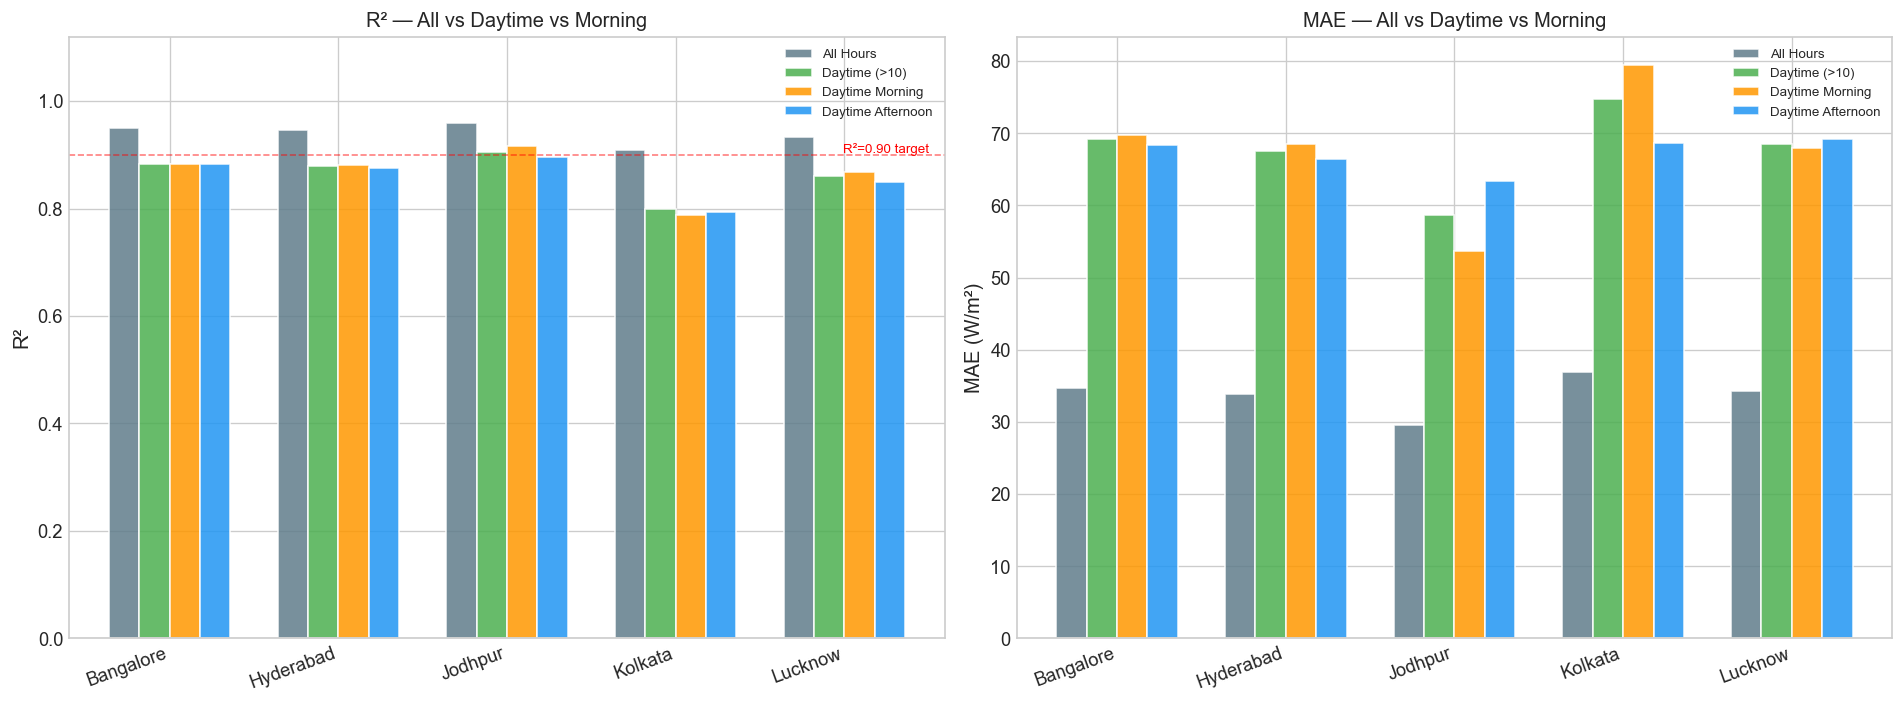

In [12]:
slices_to_plot = ['All Hours', 'Daytime (>10)', 'Daytime Morning', 'Daytime Afternoon']
plot_df = results_df[results_df['Slice'].isin(slices_to_plot)].copy()

cities   = sorted(plot_df['City'].unique())
n_cities = len(cities)
n_slices = len(slices_to_plot)
x        = np.arange(n_cities)
width    = 0.18
palette  = ['#607D8B', '#4CAF50', '#FF9800', '#2196F3']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# ── R² ────────────────────────────────────────────────────────────────────────
for i, (slc, col) in enumerate(zip(slices_to_plot, palette)):
    vals = [plot_df[(plot_df['City']==c) & (plot_df['Slice']==slc)]['R2'].values
            for c in cities]
    vals = [v[0] if len(v) else np.nan for v in vals]
    bars = ax1.bar(x + (i - n_slices/2 + 0.5)*width, vals,
                   width=width, label=slc, color=col, alpha=0.85, edgecolor='white')

ax1.axhline(0.90, color='red', linestyle='--', alpha=0.5, linewidth=1)
ax1.text(n_cities - 0.5, 0.905, 'R²=0.90 target', color='red', fontsize=8, ha='right')
ax1.set_xticks(x); ax1.set_xticklabels(cities, rotation=20, ha='right')
ax1.set_ylabel('R²'); ax1.set_title('R² — All vs Daytime vs Morning', fontsize=12)
ax1.set_ylim(0, 1.12); ax1.legend(fontsize=8)

# ── MAE ───────────────────────────────────────────────────────────────────────
for i, (slc, col) in enumerate(zip(slices_to_plot, palette)):
    vals = [plot_df[(plot_df['City']==c) & (plot_df['Slice']==slc)]['MAE'].values
            for c in cities]
    vals = [v[0] if len(v) else np.nan for v in vals]
    ax2.bar(x + (i - n_slices/2 + 0.5)*width, vals,
            width=width, label=slc, color=col, alpha=0.85, edgecolor='white')

ax2.set_xticks(x); ax2.set_xticklabels(cities, rotation=20, ha='right')
ax2.set_ylabel('MAE (W/m²)'); ax2.set_title('MAE — All vs Daytime vs Morning', fontsize=12)
ax2.legend(fontsize=8)

plt.tight_layout()
plt.savefig('results/figures/15_tod_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

## 6 · Scatter Plot — True vs Predicted (Daytime Morning, All Cities)

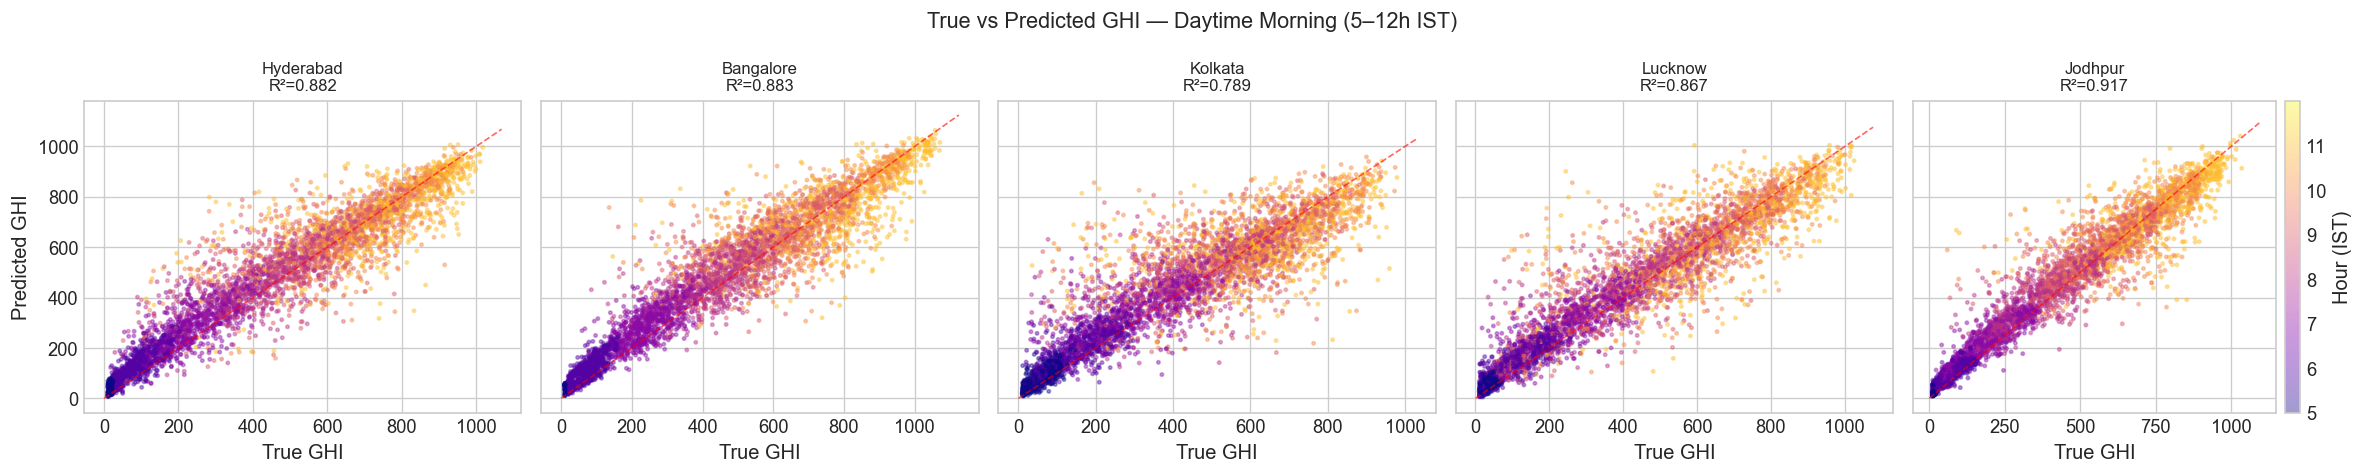

In [13]:
fig, axes = plt.subplots(1, len(get_test_cities()), figsize=(4*len(get_test_cities()), 4), sharey=True)

for ax, city in zip(axes, get_test_cities()):
    tgt_path  = f'data/processed/windows/{city}_test_targets.npy'
    pred_path = f'results/unseen_validation/pred_best_{city}.npy'
    if not (os.path.exists(tgt_path) and os.path.exists(pred_path)):
        ax.set_title(city.title()); continue

    targets_c = np.load(tgt_path)
    preds_c   = np.load(pred_path)
    N = min(len(targets_c), len(preds_c))
    hour_mat_c = get_hour_matrix(city, N)

    y_t = targets_c[:N].flatten()
    y_p = preds_c[:N].flatten()
    hrs = hour_mat_c.flatten()

    # Morning + daytime mask
    mask = (hrs >= MORNING_START) & (hrs < MORNING_END) & (y_t > GHI_THRESHOLD)

    # Subsample to keep plot fast
    idx = np.where(mask)[0]
    if len(idx) > 5000:
        idx = np.random.choice(idx, 5000, replace=False)

    sc = ax.scatter(y_t[idx], y_p[idx],
                    c=hrs[idx], cmap='plasma', s=4, alpha=0.4,
                    vmin=MORNING_START, vmax=MORNING_END)

    # Perfect prediction line
    lim = max(y_t[idx].max(), y_p[idx].max()) * 1.05
    ax.plot([0, lim], [0, lim], 'r--', linewidth=1, alpha=0.6)

    r2_val = compute_all_metrics(y_t[idx], y_p[idx])['R2']
    ax.set_title(f'{city.title()}\nR²={r2_val:.3f}', fontsize=10)
    ax.set_xlabel('True GHI')
    if ax == axes[0]:
        ax.set_ylabel('Predicted GHI')

# Colorbar for hour
cbar = fig.colorbar(sc, ax=axes[-1], pad=0.02)
cbar.set_label('Hour (IST)')
cbar.set_ticks(range(MORNING_START, MORNING_END))

plt.suptitle('True vs Predicted GHI — Daytime Morning (5–12h IST)', fontsize=13)
plt.tight_layout()
plt.savefig('results/figures/15_scatter_morning.png', dpi=200, bbox_inches='tight')
plt.show()

## 7 · Per-Hour R² Line Plot (Average across Cities)

C:\Users\SAI KRISHNA\AppData\Local\Temp\ipykernel_3432\2234596637.py:11: RuntimeWarning: Mean of empty slice
  mean_r2 = [np.nanmean([hour_r2_data[c].get(h, np.nan) for c in hour_r2_data])


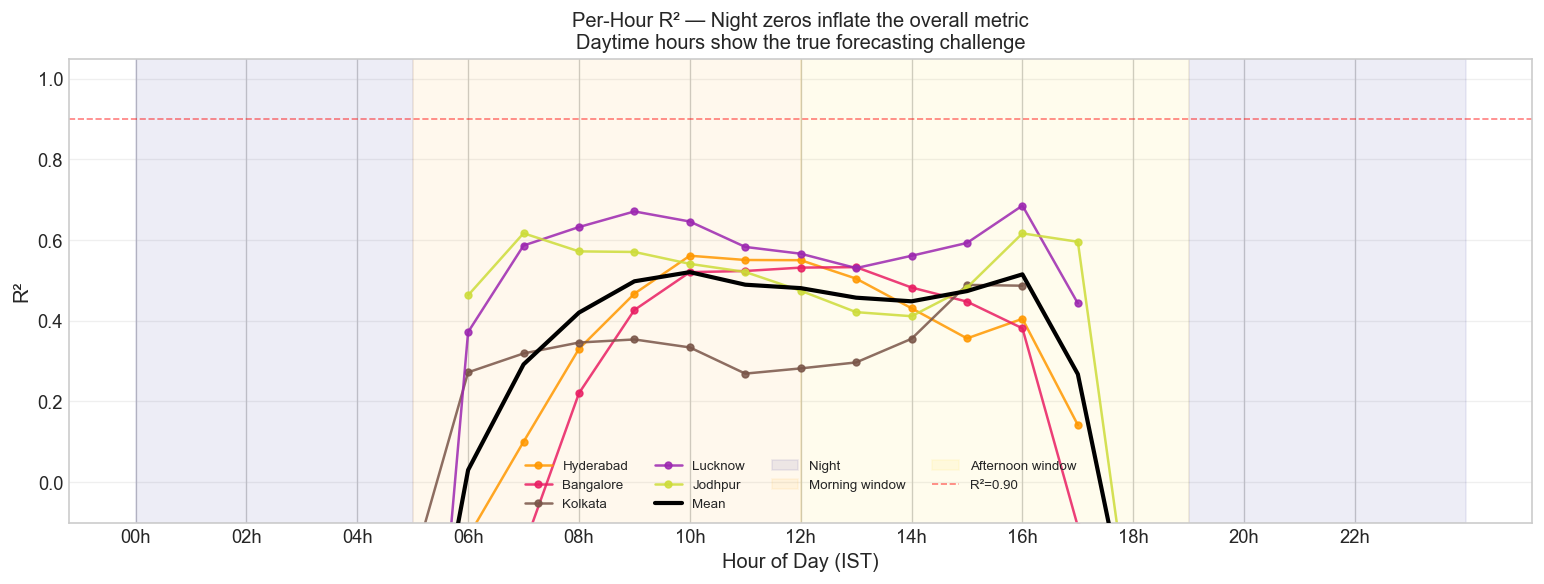

In [14]:
fig, ax = plt.subplots(figsize=(13, 5))

for city, city_data in hour_r2_data.items():
    hrs_list = sorted(city_data.keys())
    r2_list  = [city_data[h] for h in hrs_list]
    color = CITY_COLORS.get(city.lower(), None)
    ax.plot(hrs_list, r2_list, marker='o', markersize=4, linewidth=1.5,
            label=city, color=color, alpha=0.85)

# Mean across cities
mean_r2 = [np.nanmean([hour_r2_data[c].get(h, np.nan) for c in hour_r2_data])
           for h in range(24)]
ax.plot(range(24), mean_r2, 'k-', linewidth=2.5, label='Mean', zorder=5)

# Shade regions
ax.axvspan(0,    MORNING_START, color='navy',  alpha=0.07, label='Night')
ax.axvspan(MORNING_START, MORNING_END, color='orange', alpha=0.07, label='Morning window')
ax.axvspan(MORNING_END,  AFTERNOON_END, color='gold', alpha=0.07, label='Afternoon window')
ax.axvspan(AFTERNOON_END, 24,  color='navy',  alpha=0.07)

ax.axhline(0.90, color='red', linestyle='--', alpha=0.5, linewidth=1, label='R²=0.90')
ax.set_xlabel('Hour of Day (IST)', fontsize=12)
ax.set_ylabel('R²', fontsize=12)
ax.set_title('Per-Hour R² — Night zeros inflate the overall metric\n'
             'Daytime hours show the true forecasting challenge', fontsize=12)
ax.set_xticks(range(0, 24, 2))
ax.set_xticklabels([f'{h:02d}h' for h in range(0, 24, 2)])
ax.set_ylim(-0.1, 1.05)
ax.legend(fontsize=8, loc='lower center', ncol=4)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('results/figures/15_per_hour_r2.png', dpi=200, bbox_inches='tight')
plt.show()

## 8 · Summary

In [15]:
import json

# Build summary dict
summary = {}
for city in get_test_cities():
    city_rows = results_df[results_df['City'] == city.title()]
    city_dict = {}
    for _, row in city_rows.iterrows():
        city_dict[row['Slice']] = {
            'R2':   round(row['R2'],   4),
            'MAE':  round(row['MAE'],  2),
            'RMSE': round(row['RMSE'], 2),
        }
    summary[city.title()] = city_dict

os.makedirs('results/unseen_finetuned', exist_ok=True)
with open('results/daytime_evaluation_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)
results_df.to_csv('results/daytime_evaluation_results.csv', index=False)

# Final console summary
print("=" * 68)
print(f"{'City':15s} {'All R²':>8s}  {'Daytime R²':>12s}  {'Morning R²':>12s}")
print("-" * 68)
for city in get_test_cities():
    city_title = city.title()
    def _r2(slc):
        r = results_df[(results_df['City']==city_title) & (results_df['Slice']==slc)]['R2']
        return r.values[0] if len(r) else float('nan')
    print(f"  {city_title:13s} {_r2('All Hours'):>8.4f}  {_r2('Daytime (>10)'):>12.4f}  {_r2('Daytime Morning'):>12.4f}")
print("=" * 68)
print(f"\nSaved → results/daytime_evaluation_results.csv")

City              All R²    Daytime R²    Morning R²
--------------------------------------------------------------------
  Hyderabad       0.9460        0.8796        0.8820
  Bangalore       0.9494        0.8831        0.8828
  Kolkata         0.9084        0.7988        0.7886
  Lucknow         0.9333        0.8599        0.8671
  Jodhpur         0.9589        0.9060        0.9169

Saved → results/daytime_evaluation_results.csv


---
## 9 · Extra Validation — Mumbai (completely unseen city)

Mumbai is India's largest city and has **never appeared in training or test sets**.  
- Climate: **BSh** (hot semi-arid, coastal) — same Köppen class as Hyderabad/Ahmedabad  
- Lat/Lon: 19.076°N, 72.878°E  
- Data fetched live from **NASA POWER API** (test period 2022-07 → 2024-06)  
- Evaluation on **morning hours only (05–12h IST, GHI > 10 W/m²)**

In [16]:
from utils.data_utils import fetch_nasa_power_data
from utils.feature_engineering import engineer_all_features, create_sliding_windows, get_feature_columns
from utils.city_config import CITY_METADATA

# ── Register Mumbai in the global metadata so all util functions can see it ──
MUMBAI = "mumbai"
CITY_METADATA[MUMBAI] = {
    "latitude":  19.0760,
    "longitude": 72.8777,
    "elevation": 11,
    "climate_zone": "BSh",    # Hot semi-arid, coastal — like Hyderabad
    "is_coastal": True,
    "state": "Maharashtra",
    "role": "extra",
    "annual_avg_irradiance": 490,
}

print(f"Registered: {MUMBAI.title()} ({CITY_METADATA[MUMBAI]['latitude']}°N, "
      f"{CITY_METADATA[MUMBAI]['longitude']}°E, {CITY_METADATA[MUMBAI]['climate_zone']})")
print("Fetching data from NASA POWER API … (test period only: 2022-07 → 2024-06)")

# Fetch only the test period to stay fast (~2 years = 2 API chunks)
raw_df = fetch_nasa_power_data(
    city_name=MUMBAI,
    start_date="20220701",
    end_date="20240630",
    save_dir="data/raw_unseen",
)
print(f"Fetched {len(raw_df):,} rows  |  "
      f"GHI range: {raw_df['ALLSKY_SFC_SW_DWN'].min():.0f}–{raw_df['ALLSKY_SFC_SW_DWN'].max():.0f} W/m²")

Registered: Mumbai (19.076°N, 72.8777°E, BSh)
Fetching data from NASA POWER API … (test period only: 2022-07 → 2024-06)


Fetching mumbai: 100%|██████████| 3/3 [00:16<00:00,  5.52s/chunk]

Fetched 17,544 rows  |  GHI range: 0–1031 W/m²


In [17]:
# ── Feature engineering + sliding windows ────────────────────────────────────
df_mum = engineer_all_features(raw_df.copy(), MUMBAI)

# Fill any residual NaNs (e.g. rolling stats at start)
df_mum = df_mum.fillna(0)

mbai_contexts, mbai_targets, mbai_timestamps = create_sliding_windows(
    df_mum,
    context_length=CONTEXT_LENGTH,
    forecast_horizon=FORECAST_HORIZON,
    stride=STRIDE,
)

print(f"Windows created: {len(mbai_contexts)}")
print(f"  Context shape : {mbai_contexts.shape}")
print(f"  Target shape  : {mbai_targets.shape}")
print(f"  GHI (index 0) range in contexts: "
      f"{mbai_contexts[:, :, 0].min():.1f} – {mbai_contexts[:, :, 0].max():.1f} W/m²")

# Timestamps → hour-of-day matrix for every target step
mbai_hours = np.array(
    [[(t + pd.Timedelta(hours=h)).hour for h in range(FORECAST_HORIZON)]
     for t in mbai_timestamps],
    dtype=np.int8
)
print(f"  Hour matrix shape: {mbai_hours.shape}")

Windows created: 728
  Context shape : (728, 72, 34)
  Target shape  : (728, 24)
  GHI (index 0) range in contexts: 0.0 – 1030.6 W/m²
  Hour matrix shape: (728, 24)


In [19]:
import torch, os, numpy as np
from chronos import ChronosPipeline
from peft import PeftModel
from tqdm.auto import tqdm

# ── Load Chronos pipeline + LoRA adapter (fine-tuned) ────────────────────────
_device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

_pipeline = ChronosPipeline.from_pretrained(
    'amazon/chronos-t5-base',
    device_map=_device,
    torch_dtype=torch.float16,
)
_lora_path = 'models/chronos_lora'
if os.path.exists(os.path.join(_lora_path, 'adapter_model.safetensors')):
    _pipeline.model.model = PeftModel.from_pretrained(_pipeline.model.model, _lora_path)
    print("LoRA adapter loaded (fine-tuned model)")
else:
    print("No LoRA adapter found — using zero-shot Chronos")

# ── Batched Chronos prediction (same as NB07) ─────────────────────────────────
def _chronos_predict(pipeline, ghi_contexts, scales=(72, 48, 24), batch_size=16):
    scale_preds = []
    for scale in scales:
        all_med = []
        ctx = ghi_contexts[:, -scale:] if ghi_contexts.shape[1] >= scale else ghi_contexts
        for s in tqdm(range(0, len(ctx), batch_size), desc=f'scale={scale}h', leave=False):
            b = ctx[s:s+batch_size]
            means = b.mean(axis=1, keepdims=True)
            stds  = b.std(axis=1,  keepdims=True) + 1e-5
            b_norm = (b - means) / stds
            t = torch.tensor(b_norm, dtype=torch.float32)  # CPU for pipeline
            with torch.no_grad():
                samp = pipeline.predict(t, prediction_length=FORECAST_HORIZON, num_samples=20)
            samp_np = samp.cpu().numpy()
            samp_dn = np.maximum(0, samp_np * stds[:, np.newaxis, :] + means[:, np.newaxis, :])
            all_med.append(np.median(samp_dn, axis=1))
        scale_preds.append(np.concatenate(all_med, axis=0))
    return np.mean(scale_preds, axis=0)

# ── Run inference ─────────────────────────────────────────────────────────────
print(f"\nRunning inference on {len(mbai_contexts)} Mumbai windows …")
ghi_ctx = mbai_contexts[:, :, 0]          # (N, 72) — GHI channel
mbai_preds = _chronos_predict(_pipeline, ghi_ctx)
print(f"Predictions shape: {mbai_preds.shape}")

LoRA adapter loaded (fine-tuned model)

Running inference on 728 Mumbai windows …


Predictions shape: (728, 24)


Slice                      N       R²       MAE      RMSE
----------------------------------------------------------
  All Hours            17472   0.9509     31.35     64.58
  Daytime (>10)         8597   0.8916     62.50     91.85
  Morning 5-12h         4163   0.8894     61.83     91.25


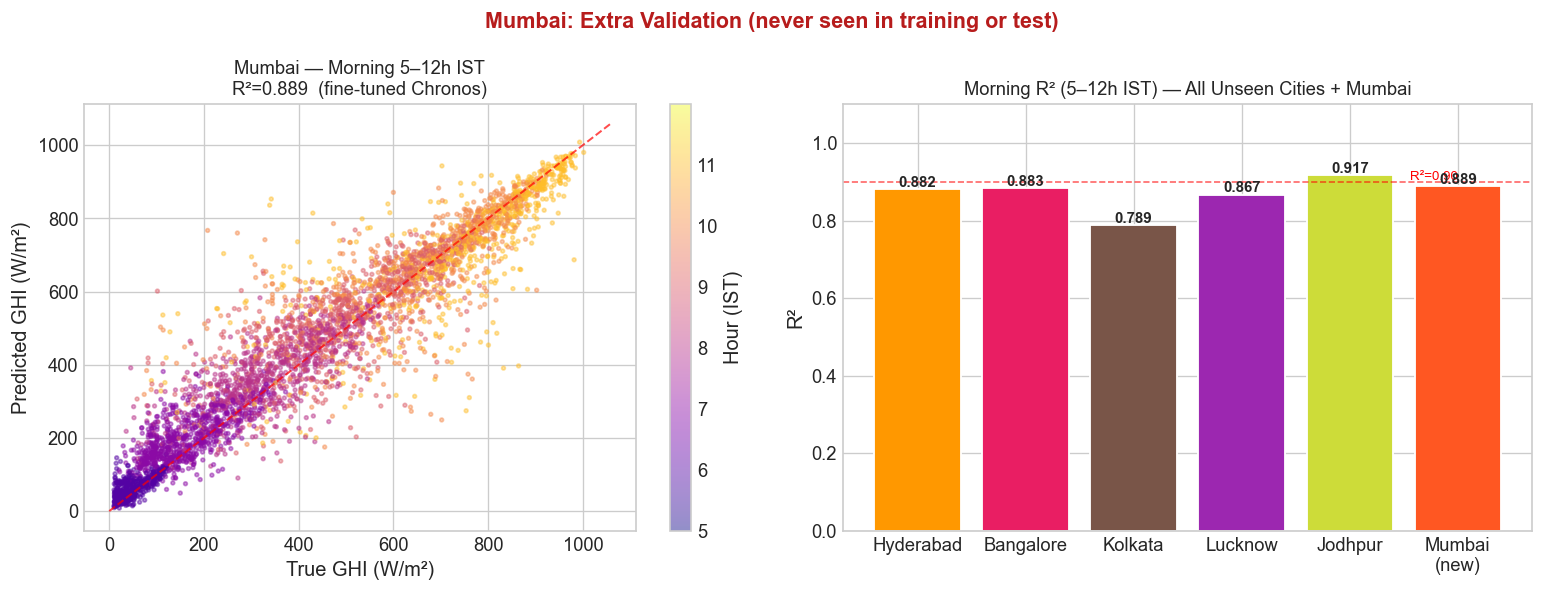


Mumbai morning R² = 0.8894


In [20]:
# ── Morning-only evaluation for Mumbai ───────────────────────────────────────
y_true_m = mbai_targets.flatten()
y_pred_m = mbai_preds.flatten()[:len(y_true_m)]
hrs_m    = mbai_hours.flatten()

mask_day_am = (hrs_m >= MORNING_START) & (hrs_m < MORNING_END) & (y_true_m > GHI_THRESHOLD)
mask_day_all = y_true_m > GHI_THRESHOLD
mask_all_h   = np.ones(len(y_true_m), dtype=bool)

slices = {
    'All Hours':      mask_all_h,
    'Daytime (>10)':  mask_day_all,
    'Morning 5-12h':  mask_day_am,
}
print(f"{'Slice':20s}  {'N':>6s}  {'R²':>7s}  {'MAE':>8s}  {'RMSE':>8s}")
print("-" * 58)
mum_metrics = {}
for name, mask in slices.items():
    if mask.sum() < 10:
        continue
    m = compute_all_metrics(y_true_m[mask], y_pred_m[mask])
    mum_metrics[name] = m
    print(f"  {name:18s}  {mask.sum():6d}  {m['R2']:7.4f}  {m['MAE']:8.2f}  {m['RMSE']:8.2f}")

# ── Scatter plot: morning hours by time-of-day ────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: scatter true vs predicted (morning, colored by hour)
idx_am = np.where(mask_day_am)[0]
if len(idx_am) > 6000:
    idx_am = np.random.choice(idx_am, 6000, replace=False)
sc = axes[0].scatter(y_true_m[idx_am], y_pred_m[idx_am],
                     c=hrs_m[idx_am], cmap='plasma', s=5, alpha=0.45,
                     vmin=MORNING_START, vmax=MORNING_END)
lim = max(y_true_m[idx_am].max(), y_pred_m[idx_am].max()) * 1.05
axes[0].plot([0, lim], [0, lim], 'r--', linewidth=1.2, alpha=0.7)
cbar = fig.colorbar(sc, ax=axes[0])
cbar.set_label('Hour (IST)'); cbar.set_ticks(range(MORNING_START, MORNING_END))
axes[0].set_xlabel('True GHI (W/m²)'); axes[0].set_ylabel('Predicted GHI (W/m²)')
r2_am = mum_metrics.get('Morning 5-12h', {}).get('R2', float('nan'))
axes[0].set_title(f'Mumbai — Morning 5–12h IST\nR²={r2_am:.3f}  (fine-tuned Chronos)', fontsize=11)

# Right: grouped R² bar for Mumbai vs other test cities (morning only)
all_city_r2 = {}
for city in get_test_cities():
    tp = f'data/processed/windows/{city}_test_targets.npy'
    pp = f'results/unseen_validation/pred_best_{city}.npy'
    if not (os.path.exists(tp) and os.path.exists(pp)):
        continue
    tgts = np.load(tp); prds = np.load(pp)
    N2 = min(len(tgts), len(prds))
    hmat = get_hour_matrix(city, N2)
    yt = tgts[:N2].flatten(); yp = prds[:N2].flatten(); hh = hmat.flatten()
    mask_am_c = (hh >= MORNING_START) & (hh < MORNING_END) & (yt > GHI_THRESHOLD)
    if mask_am_c.sum() >= 10:
        all_city_r2[city.title()] = compute_all_metrics(yt[mask_am_c], yp[mask_am_c])['R2']
all_city_r2['Mumbai\n(new)'] = mum_metrics.get('Morning 5-12h', {}).get('R2', float('nan'))

bar_colors = [CITY_COLORS.get(c.split('\n')[0].lower(), '#FF5722') for c in all_city_r2]
x_labels = list(all_city_r2.keys())
r2_vals   = list(all_city_r2.values())
bars = axes[1].bar(x_labels, r2_vals, color=bar_colors, edgecolor='white', linewidth=1.1)
axes[1].axhline(0.90, color='red', linestyle='--', alpha=0.6, linewidth=1)
axes[1].text(len(r2_vals)-1, 0.905, 'R²=0.90', color='red', fontsize=8, ha='right')
for bar, val in zip(bars, r2_vals):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.006,
                 f'{val:.3f}', ha='center', fontsize=9, fontweight='bold')
axes[1].set_ylabel('R²'); axes[1].set_ylim(0, 1.1)
axes[1].set_title('Morning R² (5–12h IST) — All Unseen Cities + Mumbai', fontsize=11)

plt.suptitle('Mumbai: Extra Validation (never seen in training or test)',
             fontsize=13, fontweight='bold', color='#B71C1C')
plt.tight_layout()
plt.savefig('results/figures/15_mumbai_morning_validation.png', dpi=200, bbox_inches='tight')
plt.show()
print(f"\nMumbai morning R² = {r2_am:.4f}")